# Entrenamiento QLoRA controlado

Proyecto 3 · Deep Learning y Sistemas Inteligentes · Sección 30

## Hipótesis registradas antes de entrenar

QLoRA `r=16` debía reducir el costo manteniendo capacidad suficiente. QLoRA `r=32` podía mejorar la composición de consultas medias y difíciles, a cambio de más parámetros y tiempo. La ganancia podía ser nula si la calidad de los datos era el límite.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "config.json").exists(), "Ejecuta el notebook desde la raíz o notebooks/."
ARTIFACTS = Path(os.environ.get("PROJECT3_ARTIFACTS", ROOT.parent / "artifacts_locales"))
SEED = 2026
print({"root": str(ROOT), "artifacts": str(ARTIFACTS), "seed": SEED})

{'root': 'C:\\Users\\Daniel\\Desktop\\Proyecto-3_Deep\\Proyecto-3_Grupo-1_DLYSI_Sec-30', 'artifacts': 'C:\\Users\\Daniel\\Desktop\\Proyecto-3_Deep\\artifacts_locales', 'seed': 2026}


## 1. Hardware disponible para reproducir

In [2]:
import torch

hardware = {'cuda': torch.cuda.is_available()}
if torch.cuda.is_available():
    properties = torch.cuda.get_device_properties(0)
    hardware.update({'gpu': torch.cuda.get_device_name(0), 'vram_gib': round(properties.total_memory / 1024**3, 2)})
hardware

{'cuda': True, 'gpu': 'NVIDIA GeForce RTX 4050 Laptop GPU', 'vram_gib': 6.0}

## 2. Comparación controlada

In [3]:
a = json.loads((ROOT / 'configuraciones/qlora_r16.json').read_text(encoding='utf-8'))
b = json.loads((ROOT / 'configuraciones/qlora_r32.json').read_text(encoding='utf-8'))
differences = {key: (a.get(key), b.get(key)) for key in sorted(a | b) if a.get(key) != b.get(key)}
assert set(differences) <= {'nombre', 'r'}
differences

{'nombre': ('qlora_r16', 'qlora_r32'), 'r': (16, 32)}

## 3. Entrenamiento opcional

Las corridas reales ya finalizaron. La bandera evita reentrenar al ejecutar este notebook como evidencia.

In [4]:
RUN_FULL_TRAINING = False
if RUN_FULL_TRAINING:
    for name in ('qlora_r16', 'qlora_r32'):
        output = ARTIFACTS / 'runs' / name
        subprocess.run([sys.executable, str(ROOT / 'scripts/train_qlora.py'), '--config', str(ROOT / f'configuraciones/{name}.json'), '--output', str(output)], check=True)
else:
    print('No se reentrenó: se muestran los resultados y curvas versionados.')

No se reentrenó: se muestran los resultados y curvas versionados.


## 4. Parámetros, tiempo y selección

In [5]:
import pandas as pd

summary = json.loads((ROOT / 'resultados/resumen.json').read_text(encoding='utf-8'))
pd.DataFrame([
    {'corrida': name, **summary['experiments'][name]}
    for name in ('qlora_r16', 'qlora_r32')
])[['corrida', 'trainable_parameters', 'training_minutes', 'weighted_ex', 'executable_rate', 'latency_p95_ms']]

,corrida,trainable_parameters,training_minutes,weighted_ex,executable_rate,latency_p95_ms
0,qlora_r16,18464768,120.682453,0.974359,0.975,15718.6631
1,qlora_r32,36929536,133.424624,0.974359,0.975,13197.0874


## 5. Curvas reales de loss

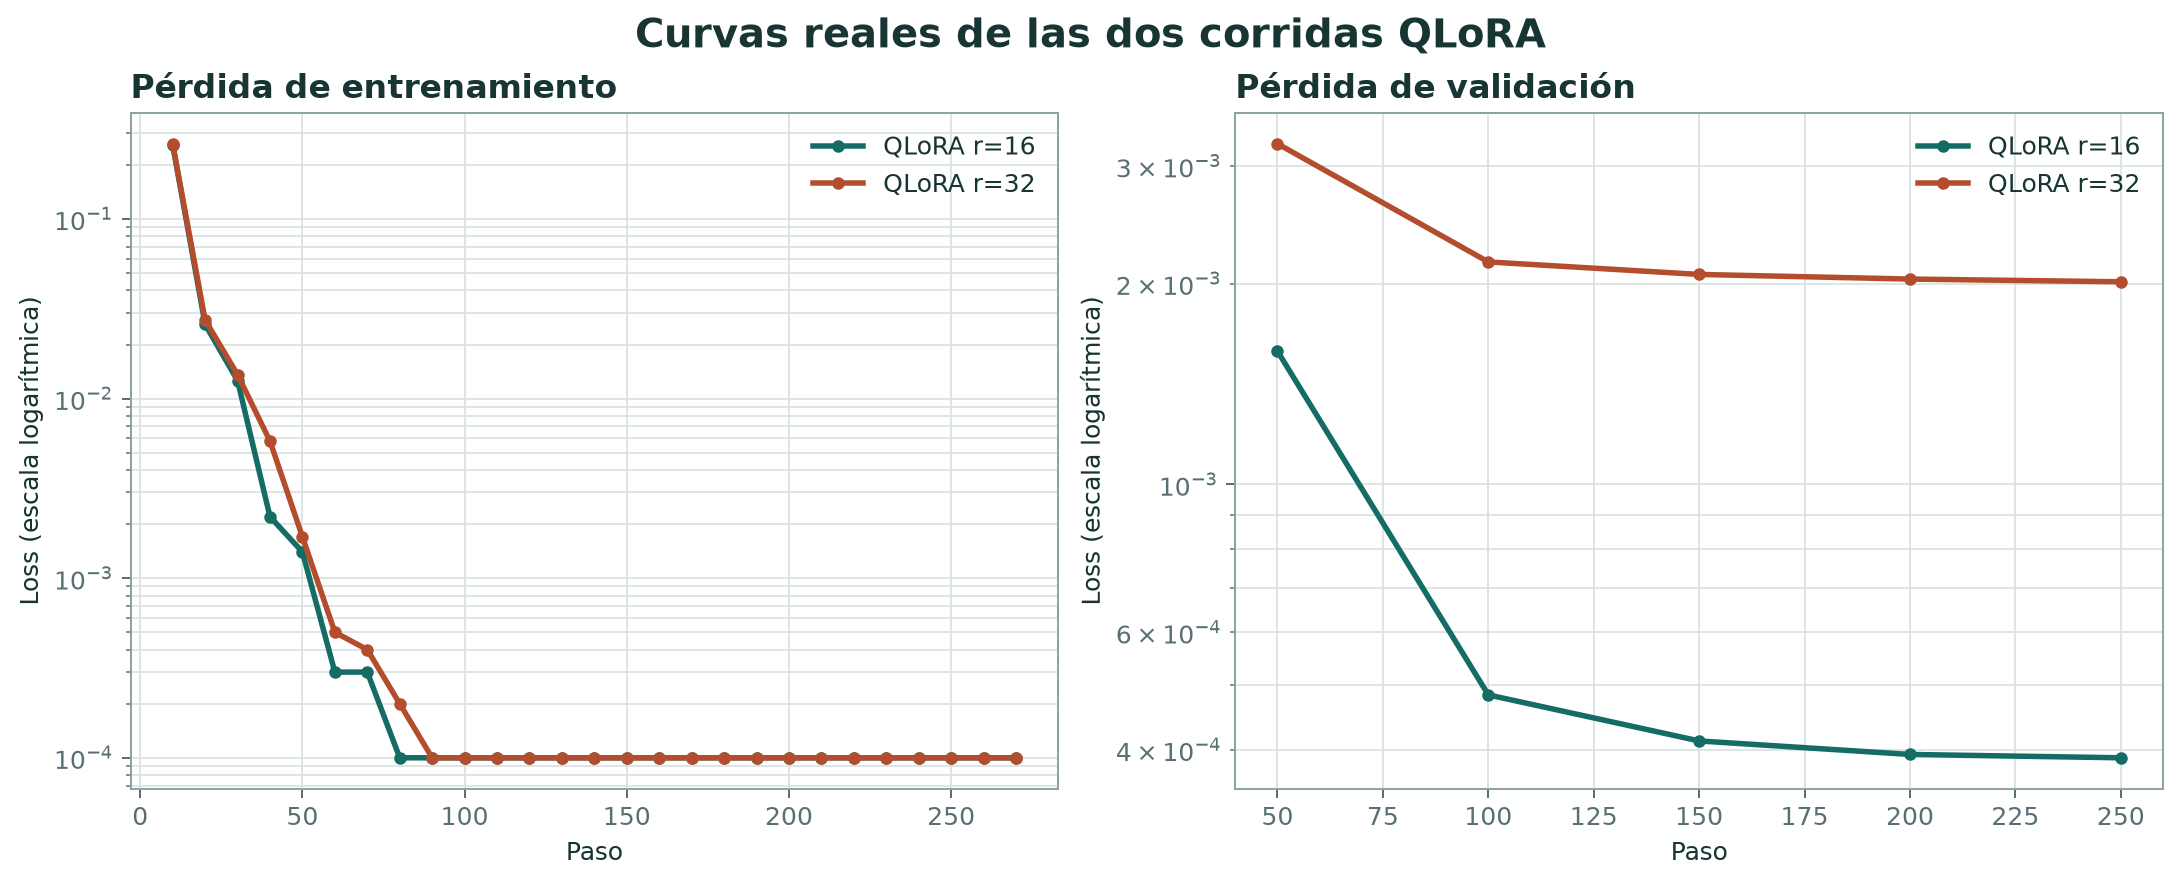

{'status': 'exported_from_completed_training',
 'series': ['train', 'validation'],
 'runs': {'qlora_r16': {'checkpoint': 'checkpoint-270',
   'sha256': '158d6b5d8192d91c919024cfe0ee535c883397d9d6064f229dbfd2cecf5e4b66',
   'train_points': 27,
   'validation_points': 5},
  'qlora_r32': {'checkpoint': 'checkpoint-270',
   'sha256': '96baf11bb6d1434f8420ed59a4c22a7216e46c6612da43c28bcc26d78593d490',
   'train_points': 27,
   'validation_points': 5}},
 'csv': 'curvas_loss.csv',
 'chart': 'curvas_loss.png'}

In [6]:
from IPython.display import Image, display

curves = pd.read_csv(ROOT / 'resultados/curvas_loss.csv')
metadata = json.loads((ROOT / 'resultados/curvas_loss.json').read_text(encoding='utf-8'))
assert set(curves['run']) == {'qlora_r16', 'qlora_r32'}
assert set(curves['series']) == {'train', 'validation'}
display(Image(filename=str(ROOT / 'resultados/curvas_loss.png')))
metadata

## Resultado

`r=16` entrenó 18,464,768 parámetros durante 120.7 minutos. `r=32` entrenó 36,929,536 durante 133.4 minutos. Ambas corridas alcanzaron 97.4% de EX; `r=32` ganó por menor latencia p95.